In [1]:
import pyC2C as c2c
import matplotlib.pyplot as plt
import io

### Parameters dictionary
- parameters are written in exported ppt file

In [ ]:
parameters = dict()

parameters['ms filepath'] = 'sample_data/shimadzu_C2C005'
parameters['sample'] = 'C2C005'
parameters['modulation time'] = 4

### Load data file

In [3]:
ms_data = c2c.load_file(parameters['ms filepath'])
ms_data.readTIC()
ms_data.getBPC()

0
10000
20000
30000
40000
50000
60000
70000
80000
90000
100000
Number of MS1 scans: 106680


### Find intensity cut-off for MS scans

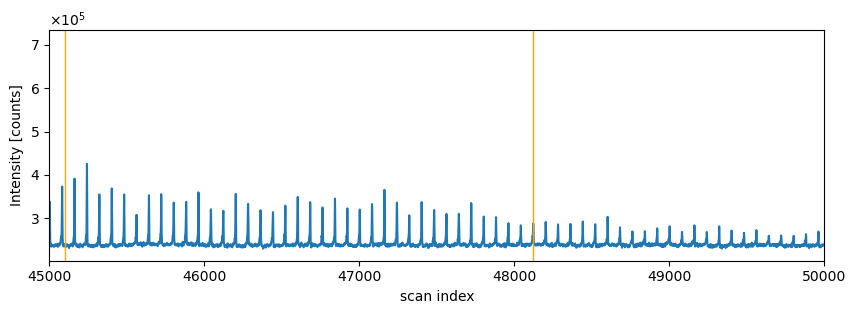

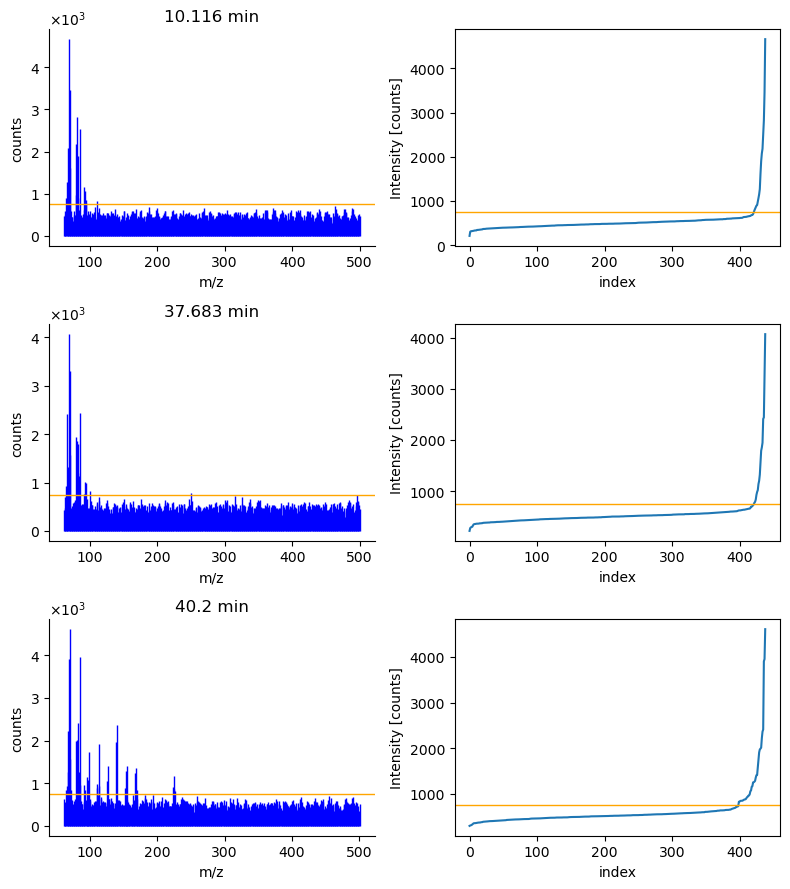

In [4]:
idx_list = [12019, 45100, 48120] # scan numbers to plot
parameters['scan inty cutoff'] = 750

tic_fig, tic_ax = plt.subplots(figsize=(10, 3))

tic_ax.plot(range(len(ms_data.rt)), ms_data.tic)
tic_ax.set_xlabel('scan index')
tic_ax.set_ylabel('Intensity [counts]')
tic_ax.ticklabel_format(style='sci', useMathText=True, scilimits=(0, 3), axis='y')
tic_ax.set_xlim(45000, 50000)

fig, ax = plt.subplots(len(idx_list), 2, figsize=(8, len(idx_list) * 3))

for i, idx in enumerate(idx_list):
    tic_ax.axvline(x=idx, color='orange', lw=1)
    ms_data.MS1Data[idx].plotScan(ax[i, 0], annotation = False)
    ax[i, 0].spines['top'].set_visible(False)
    ax[i, 0].spines['right'].set_visible(False)
    ax[i, 0].axhline(y=parameters['scan inty cutoff'], color='orange', lw=1)

    ax[i, 1].plot(range(len(ms_data.MS1Data[idx].intensity)), sorted(ms_data.MS1Data[idx].intensity))
    ax[i, 1].axhline(y=parameters['scan inty cutoff'], color='orange', lw=1)
    ax[i, 1].set_ylabel('Intensity [counts]')
    ax[i, 1].set_xlabel('index')

plt.tight_layout()
plt.show()

Refreshing TIC and BPC...


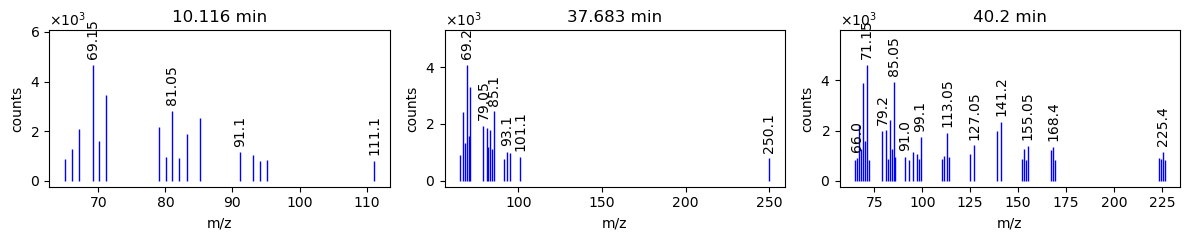

In [5]:
# go through all MS scans and remove m/z under cut-off. Refreshes TIC and BPC
ms_data.intyCutoff(cutoff=parameters['scan inty cutoff'])

# plot scans from above after intensity cut-off
fig, ax = plt.subplots(1, len(idx_list), figsize= (len(idx_list) * 4, 2.5))

for i, idx in enumerate(idx_list):

    ms_data.MS1Data[idx].plotScan(ax[i], annotation=True)

plt.tight_layout()
plt.show()

### Start ChromAnalyzer
- pick signals from FID or MS data
- combine them with respect to modulation time
- remove peaks with low intensity
- get 2d RT
- integrate MS1 scans
- export as csv and pptx

In [6]:
data_analysis = c2c.ChromAnalyzer(ms_data.rt, ms_data.bpc, msfile=ms_data) # only MS data available

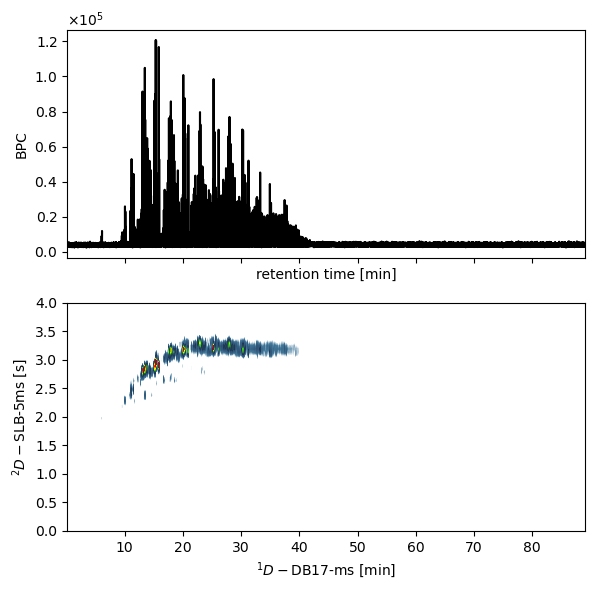

In [7]:
# 1D and 2D plots with TIC
parameters['shift'] = 1
parameters['solvent cut'] = 0

xmin = None
xmax = None

fig, ax = plt.subplots(2, figsize=(6, 6), sharex=True)

c2c.plot1d(ax[0], ms_data.rt, ms_data.bpc, linecolor='black')
c2c.plot2d(fig, ax[1], ms_data.rt, ms_data.bpc,
           mod_time=parameters['modulation time'], 
           shift=parameters['shift'],
           color_range=(8, 80), cbar=False,
           axis_labels=('DB17-ms', 'SLB-5ms'),
           solvent_cut=parameters['solvent cut'])

ax[0].set_ylabel('BPC')
ax[0].ticklabel_format(style='sci', scilimits = (0, 3), useMathText=True, axis='y')
ax[0].set_xlim(xmin, xmax)
ax[1].set_xlim(xmin, xmax)

plt.tight_layout()

# save image for report later
chromatogram_img = io.BytesIO()
plt.savefig(chromatogram_img)
plt.show()

#### pick signals

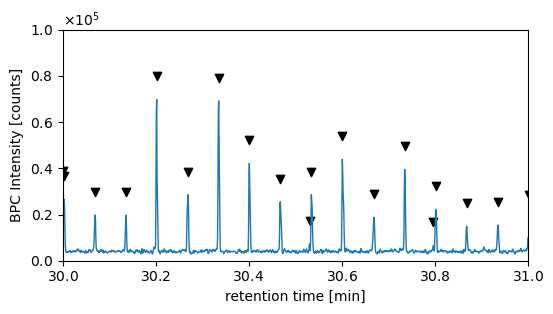

In [11]:
xmin = 30
xmax = 31
ymin = 0
ymax = 1e5

parameters['prominence'] = 0.1e3
parameters['minimum peak height'] = 0.6e4
 
fig, ax = plt.subplots(figsize=(6, 3))

data_analysis.pickSignals(ax, prominence=parameters['prominence'], 
                          height=parameters['minimum peak height'], 
                          solvent_cut=parameters['solvent cut'], 
                          marker_offset=1e4)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_ylabel('BPC Intensity [counts]')
ax.set_xlabel('retention time [min]')
ax.set_title('')

signals_img = io.BytesIO()
plt.savefig(signals_img)

plt.show()

#### combine signals

In [12]:
parameters['modulation time tolerance'] = 0.25

data_analysis.timeCluster(modtime=parameters['modulation time'], 
                          time_tol=parameters['modulation time tolerance']) # modulation time and time tolerance in seconds!
data_analysis.combineSignals(modtime=parameters['modulation time'], 
                             shift=parameters['shift'])

print('Number of combined features: %i' % len(data_analysis.combined_signals))

Number of combined features: 183


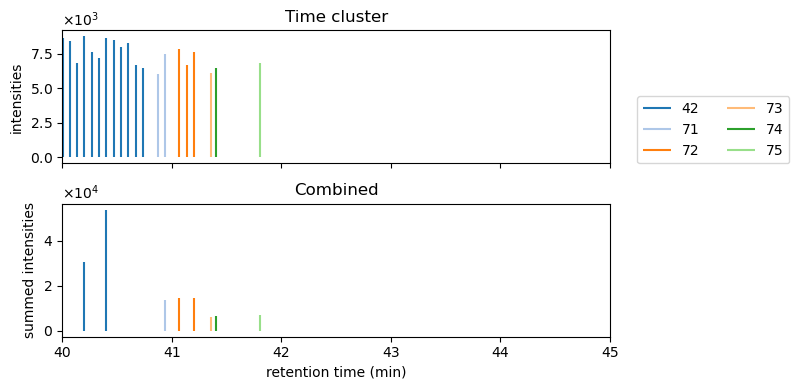

In [13]:
data_analysis.plotCluster(xmin=40, xmax=45)

#### remove peaks with low intensities

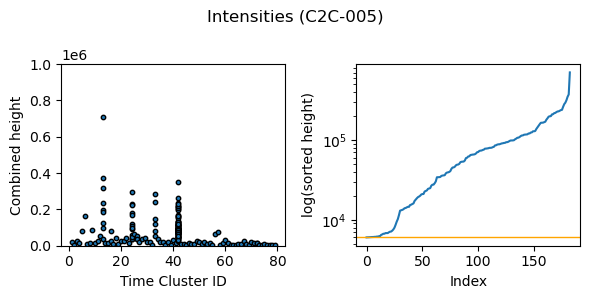

In [14]:
parameters['peak inty threshold'] = 6e3

fig, ax = plt.subplots(1, 2, figsize=(6, 3))

ax[0].scatter(data_analysis.combined_signals['Time Cluster ID'], data_analysis.combined_signals['Height'],
           s= 10, edgecolors='black')

ax[0].set_ylabel('Combined height')
ax[0].set_xlabel('Time Cluster ID')

removed = data_analysis.combined_signals[data_analysis.combined_signals['Height'] <= parameters['peak inty threshold']]
features = data_analysis.combined_signals[data_analysis.combined_signals['Height'] > parameters['peak inty threshold']]

ax[0].scatter(removed['Time Cluster ID'], removed['Height'], s= 10, c='orange')

ax[1].plot(sorted(data_analysis.combined_signals['Height']))
ax[1].axhline(y=parameters['peak inty threshold'], color='orange', linewidth = 1)
ax[1].set_yscale('log')
ax[1].set_ylabel('log(sorted height)')
ax[1].set_xlabel('Index')
#ax[1].set_ylim(5e3, 1e4)

ax[0].set_ylim(0, 1e6)

fig.suptitle('Intensities (%s)' %parameters['sample'])

plt.tight_layout()
lowInty_img = io.BytesIO()
plt.savefig(lowInty_img)
plt.show()

In [15]:
# integration of QToF data uses m/z clustering before to lower the resolution
# takes some minutes
# data_analysis.integrateMSScans(simplify=True, mz_tol_fixed=0.05, mz_tol_ppm=10)

data_analysis.integrateMSScans() # if shimadzu data, no clustering is needed (simplify=False is default value of method)
data_analysis.results.head()

0
20
40
60


,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1
0,6.1158,6.10,1.95,21049.0,1,66.05:7.42 67.0:6.38 67.1:25.33 67.15:9.37 67....
1,6.0708,6.03,3.25,6014.0,2,65.0:25.09 66.0:20.43 66.1:8.64 67.1:50.38 68....
2,9.5858,9.57,2.15,26802.0,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...
3,9.7208,9.70,2.25,13021.0,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...
4,10.0542,10.03,2.25,82421.0,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...


In [ ]:
# create ppt report with parameters and MS scans
c2c.exportMSScans(data_analysis.results, 
                  ppt_fout='sample_data/c2c_005_MSScans.pptx',
                  parameters=parameters,
                  img_list=[chromatogram_img, signals_img, lowInty_img])

### Plot with cluster ID

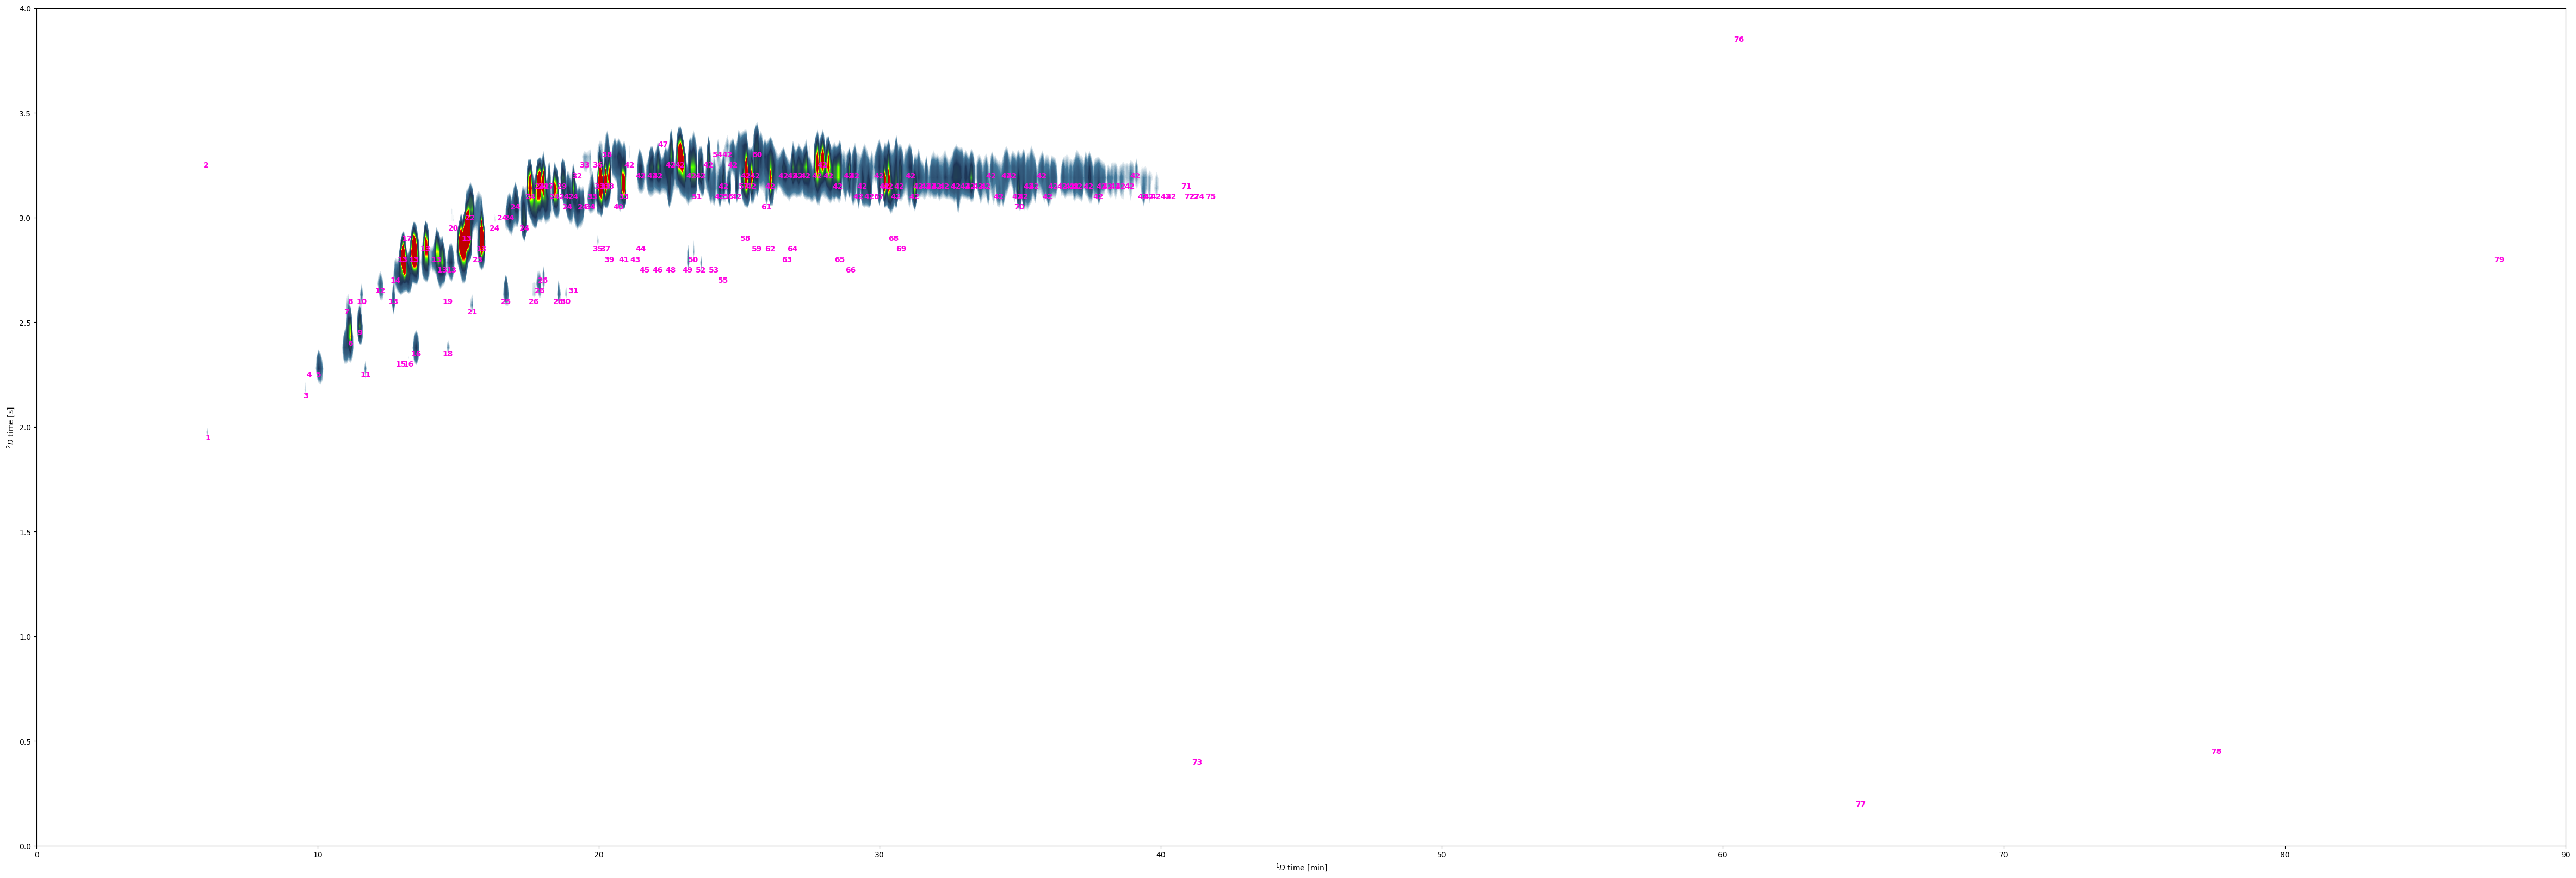

In [17]:
xmin = 0
xmax = 90

ymin = 0
ymax = 4

fig, ax = plt.subplots(figsize=(60, 20))

c2c.plot2d(fig, ax, ms_data.rt, ms_data.bpc, 4, shift=parameters['shift'], cbar=False, color_range=(8, 50))

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

peaks = data_analysis.results[data_analysis.results['Height'] >= parameters['peak inty threshold']]
removed = data_analysis.results[data_analysis.results['Height'] < parameters['peak inty threshold']]

ax.scatter(removed['RT 1d (min)'], removed['RT 2d (s)'], marker='x', color='orange')

for k in range(len(peaks)):
    rt1 = peaks.loc[peaks.index[k], 'RT 1d (min)']
    rt2 = peaks.loc[peaks.index[k], 'RT 2d (s)']
    if xmin <= rt1 <= xmax and ymin <= rt2 <= ymax:
        ax.text(rt1, rt2, 
                s=peaks.loc[peaks.index[k], 'Time Cluster ID'],
                va = 'center', ha='center', color="#FF00E1", fontdict=dict({'fontweight': 'bold'}))

plt.show()

In [ ]:
# save combined features with are not removed because of low intensity
peaks.to_csv('sample_data/c2c_005_MSScans.csv', sep=',', index=False)